In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("titanic.csv")

In [ ]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
df.shape

(891, 15)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [ ]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [ ]:
df.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,object
who,object


In [ ]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [ ]:
df.duplicated().sum()

np.int64(107)

In [ ]:
df.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,object
who,object


In [ ]:
df['age'] = df['age'].fillna(df['age'].mean())

In [ ]:
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df = df.drop(columns=['deck'])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

In [ ]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


In [ ]:
df.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,object
who,object


In [ ]:
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.000000,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.000000,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.000000,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.000000,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.000000,0,0,8.0500,S,Third,man,True,Southampton,no,True
5,0,3,male,29.699118,0,0,8.4583,Q,Third,man,True,Queenstown,no,True
6,0,1,male,54.000000,0,0,51.8625,S,First,man,True,Southampton,no,True
7,0,3,male,2.000000,3,1,21.0750,S,Third,child,False,Southampton,no,False
8,1,3,female,27.000000,0,2,11.1333,S,Third,woman,False,Southampton,yes,False
9,1,2,female,14.000000,1,0,30.0708,C,Second,child,False,Cherbourg,yes,False


In [ ]:
df['sex'] = df['sex'].str.strip().str.lower()
df['embark_town'] = df['embark_town'].str.strip().str.lower()

In [ ]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

In [ ]:
df = pd.get_dummies(
    df,
    columns=['sex'],
    dtype=int
)

In [ ]:
df.head()

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,sex_female,sex_male
0,0,3,22.0,1,0,7.2500,S,Third,man,True,southampton,no,False,0,1
1,1,1,38.0,1,0,71.2833,C,First,woman,False,cherbourg,yes,False,1,0
2,1,3,26.0,0,0,7.9250,S,Third,woman,False,southampton,yes,True,1,0
3,1,1,35.0,1,0,53.1000,S,First,woman,False,southampton,yes,False,1,0
4,0,3,35.0,0,0,8.0500,S,Third,man,True,southampton,no,True,0,1


In [ ]:
df.dtypes

,0
survived,int64
pclass,int64
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,object
who,object
adult_male,bool


In [ ]:
categorical_cols = [
    'alive',
    'who',
    'embarked',
    'class',
    'embark_town'
]

In [ ]:
df = pd.get_dummies(
    df,
    columns=categorical_cols,
    dtype=int
)

In [ ]:
df.dtypes

,0
survived,int64
pclass,int64
age,float64
sibsp,int64
parch,int64
fare,float64
adult_male,bool
alone,bool
sex_female,int64
sex_male,int64


In [ ]:
df.head()

,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_female,sex_male,...,who_woman,embarked_C,embarked_Q,embarked_S,class_First,class_Second,class_Third,embark_town_cherbourg,embark_town_queenstown,embark_town_southampton
0,0,3,22.0,1,0,7.2500,True,False,0,1,...,0,0,0,1,0,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,False,False,1,0,...,1,1,0,0,1,0,0,1,0,0
2,1,3,26.0,0,0,7.9250,False,True,1,0,...,1,0,0,1,0,0,1,0,0,1
3,1,1,35.0,1,0,53.1000,False,False,1,0,...,1,0,0,1,1,0,0,0,0,1
4,0,3,35.0,0,0,8.0500,True,True,0,1,...,0,0,0,1,0,0,1,0,0,1


In [ ]:
original_df = df[['age', 'fare']].copy()

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
"""
num_cols = [
    'age',
    'fare'
]
"""
scaler = MinMaxScaler()

df[['age']] = scaler.fit_transform(df[['age']])
df[['fare']] = scaler.fit_transform(df[['fare']])


In [ ]:
df.head()

,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_female,sex_male,...,who_woman,embarked_C,embarked_Q,embarked_S,class_First,class_Second,class_Third,embark_town_cherbourg,embark_town_queenstown,embark_town_southampton
0,0,3,0.271174,1,0,0.014151,True,False,0,1,...,0,0,0,1,0,0,1,0,0,1
1,1,1,0.472229,1,0,0.139136,False,False,1,0,...,1,1,0,0,1,0,0,1,0,0
2,1,3,0.321438,0,0,0.015469,False,True,1,0,...,1,0,0,1,0,0,1,0,0,1
3,1,1,0.434531,1,0,0.103644,False,False,1,0,...,1,0,0,1,1,0,0,0,0,1
4,0,3,0.434531,0,0,0.015713,True,True,0,1,...,0,0,0,1,0,0,1,0,0,1


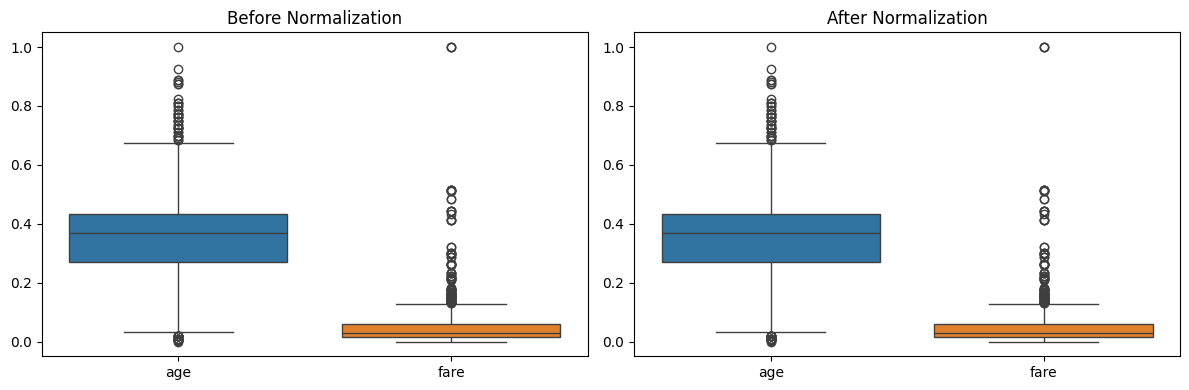

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=original_df, ax=axes[0])
axes[0].set_title("Before Normalization")

sns.boxplot(data=df[['age', 'fare']], ax=axes[1])
axes[1].set_title("After Normalization")

plt.tight_layout()
plt.show()

In [ ]:
print("Before Normalization:")
print(original_df[['age', 'fare']].describe())

print("After Normalization:")
print(df[['age', 'fare']].describe())

Before Normalization:
              age        fare
count  891.000000  891.000000
mean     0.367921    0.062858
std      0.163383    0.096995
min      0.000000    0.000000
25%      0.271174    0.015440
50%      0.367921    0.028213
75%      0.434531    0.060508
max      1.000000    1.000000
After Normalization:
              age        fare
count  891.000000  891.000000
mean     0.367921    0.062858
std      0.163383    0.096995
min      0.000000    0.000000
25%      0.271174    0.015440
50%      0.367921    0.028213
75%      0.434531    0.060508
max      1.000000    1.000000
